# Results interpretation figures

Consolidated notebook replacing `CounterfactualPlotsWeibullSpain.ipynb` and `CounterfactualPlotsWeibullGermany.ipynb`.

Calibrates Weibull mixture models to decomposition moments for Spain (v21) and Germany, simulates hazard rates under three scenarios (Heterogeneity+DD, Heterogeneity only, Exponential), and produces Figures 2 and Appendix het\_DD\_base.

**Run cells top-to-bottom** — Germany figures depend on Spain simulation variables.

**Outputs:**
- `data/intermediate/germany/exp_dur_base.png` — Figure 2
- `data/intermediate/germany/het_DD_base.png` — Appendix figure
- `spa_sim_invHaz_ksame_21.csv`, `spa_sim_invHaz_k1_21.csv`, `spa_sim_invHaz_expo_21.csv` (also used by `CounterfactualPlotsWeibullGermanyT.ipynb`)
- `ger_sim_invHaz_ksame.csv`, `ger_sim_invHaz_k1.csv`, `ger_sim_invHaz_expo.csv`

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sn
import csv
from scipy.optimize import least_squares, minimize
from scipy.stats import weibull_min as weibull
from scipy.special import gamma

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.options.display.float_format = "{:,}".format
sn.set_style("whitegrid")
%matplotlib inline

In [2]:
# ── Exponential CDF helpers ───────────────────────────────────────────────
def expo_cdf(x, max_dur=95, start=1):
    return 1 - 1/np.exp(x * np.arange(start, max_dur))

def ssr_cdf(x, other_cdf, start):
    return other_cdf - expo_cdf(x, max_dur=other_cdf.size + start, start=start)

# ── Decomposition log parser ───────────────────────────────────────────────
def pass_to_csv(file_name, path_res, path_out="", keyword="Variable"):
    results_now = 0
    table_num = 0
    if path_out == "":
        path_out = path_res
    with open(path_res + file_name + ".log") as file:
        lines = file.read().splitlines()
        output = []
        for line in lines:
            line = line.replace("|", "")
            words = line.split()
            if len(words) > 1 and words[0] == "Variable":
                results_now = 1
            if len(words) > 5 and results_now:
                output.append(line.split())
            if len(words) > 5 and words[0] == "mu_y":
                results_now = 0
                fname = (path_out + file_name + ".csv" if table_num == 0
                         else path_out + file_name + "_{}.csv".format(table_num + 1))
                with open(fname, "w+") as csvfile:
                    csv.writer(csvfile).writerows(output)
                table_num += 1
                output = []

def first_format(dataset, label):
    dataset["N"] = dataset.loc["Obs"].iloc[0]
    dataset["N"] = dataset["N"].apply(lambda x: x.replace(",", ""))
    dataset["N"] = dataset["N"].apply(lambda x: float(x)/2).apply(lambda x: "{:,.0f}".format(float(x)))
    dataset = dataset.rename(index={"Mean": label})
    return dataset.loc[label].copy()

# ── Variance decomposition ─────────────────────────────────────────────────
def decompose_logs(data_ht):
    N = data_ht.shape[0]
    mu_y = np.average(data_ht)
    data_ht["lmu_i"]  = (np.log(data_ht.n1) + np.log(data_ht.n2)) / 2
    data_ht["lmu_y"]  = np.sum(np.log(data_ht.n1) + np.log(data_ht.n2)) / (2*N)
    data_ht["lsig_i"] = (np.log(data_ht.n1) - np.log(data_ht.n2))**2 / 2
    data_ht["lsig_y"] = np.sum(np.log(data_ht.n1)**2 + np.log(data_ht.n2)**2
                                - 2*data_ht["lmu_y"]**2) / (2*N - 1)
    data_ht["lsig_w"] = np.sum(data_ht["lsig_i"]) / N
    data_ht["lsig_b"] = (np.sum(data_ht["lmu_i"]**2 - 0.5*data_ht["lsig_i"]) / N
                          - data_ht["lmu_y"]**2 + data_ht["lsig_y"] / (2*N))
    data_ht["lsig_c"] = np.pi**2 / 6
    data_ht["lsig_e"] = data_ht["lsig_w"] - data_ht["lsig_c"]
    row = data_ht.iloc[0]
    return mu_y, row["lsig_y"], row["lsig_c"], row["lsig_b"], row["lsig_e"]

In [3]:
def get_params_2l1k(moms):
    """Returns lambda, alpha and k such that the data generation process is 
       a mixture of two Weibull distributions with identical k parameter:
    t -> Mix ( Weibull(lambda,k) , Weibull(lambda*alpha,k) ) with equal weights.
    """
    mu_y, lsig_b, lsig_w  = moms
    k = np.pi / np.sqrt(6*lsig_w)
    alpha = np.exp(2*np.sqrt(lsig_b))
    lbda = 2*mu_y / ( gamma(1+1/k)* (1+alpha))
    return lbda, alpha, k

## Load Decomposition Results

In [4]:
# Spain (v21)
spa_path_res = "./data/intermediate/spain/results/"
spa_path_out = "./data/intermediate/spain/results/"
pass_to_csv("results2011_T_harm", spa_path_res, path_out=spa_path_out)
spa_res_11 = pd.read_csv(spa_path_out + "results2011_T_harm.csv", index_col=0).T
spa_res_11 = first_format(spa_res_11, "Spain")

# Germany
ger_path_res = "./data/intermediate/germany/"
pass_to_csv("031_decomp_2011", ger_path_res)
ger_res_11 = pd.read_csv(ger_path_res + "031_decomp_2011.csv", index_col=0).T
ger_res_11 = first_format(ger_res_11, "Germany")

# Moments: [mu_y, lsig_y2, lsig_b2, lsig_e2]
spa_moms = np.array([spa_res_11.mu_y, spa_res_11.lsig_y2, spa_res_11.lsig_b2, spa_res_11.lsig_e2])
ger_moms = np.array([ger_res_11.mu_y, ger_res_11.lsig_y2, ger_res_11.lsig_b2, ger_res_11.lsig_e2])

print("Spain moments  (mu_y, lsig_y2, lsig_b2, lsig_e2):", np.round(spa_moms, 4))
print("Germany moments:", np.round(ger_moms, 4))

Spain moments  (mu_y, lsig_y2, lsig_b2, lsig_e2): [ 9.124471e+02  1.855500e+00  1.617000e-01 -4.940000e-02]
Germany moments: [3.601755e+02 2.567900e+00 1.859000e-01 6.944000e-01]


Same but for only temporary spells

In [5]:
# Spain
spa_path_res = "./data/intermediate/spain/results/"
spa_path_out = "./data/intermediate/spain/results/"
# Baseline decomp
pass_to_csv("results2011_onlyT_harm",spa_path_res, path_out=spa_path_out)
spa_resT_11 = pd.read_csv(spa_path_out+"results2011_onlyT_harm.csv",index_col=0).T
spa_resT_11 = first_format(spa_resT_11,'Spain')

# Germany
ger_path_res = "./data/intermediate/germany/"
# Baseline decomp
pass_to_csv("041_decomp",ger_path_res)
ger_resT = pd.read_csv(ger_path_res+"041_decomp.csv",index_col=0).T
ger_resT = first_format(ger_resT,'Germany')

# Moments: [mu_y, lsig_y2, lsig_b2, lsig_e2]
spa_momsT = np.array([spa_resT_11.mu_y, spa_resT_11.lsig_y2, spa_resT_11.lsig_b2, spa_resT_11.lsig_e2])
ger_momsT = np.array([ger_resT.mu_y, ger_resT.lsig_y2, ger_resT.lsig_b2, ger_resT.lsig_e2])

print("Spain moments, only temp  (mu_y, lsig_y2, lsig_b2, lsig_e2):", np.round(spa_momsT, 4))
print("Germany moments, only temp:", np.round(ger_momsT, 4))

Spain moments, only temp  (mu_y, lsig_y2, lsig_b2, lsig_e2): [ 3.918801e+02  1.783100e+00  3.203000e-01 -1.821000e-01]
Germany moments, only temp: [ 5.240515e+02  1.716100e+00  9.240000e-02 -4.080000e-02]


## Spain: Analytical derivation



In [6]:
spa_lambda_0, spa_alpha_0, spa_k_0 = get_params_2l1k([spa_moms[0],spa_moms[2],spa_moms[3]+np.pi**2/6])
spa_lambda_0, spa_alpha_0, spa_k_0 

(np.float64(567.6953394374325),
 np.float64(2.2349505987830587),
 np.float64(1.015358917126788))

In [7]:
np.random.seed(42)
_spa_check = np.vstack((
    weibull.rvs(c=spa_k_0, scale=spa_lambda_0,             size=(500_000, 2)),
    weibull.rvs(c=spa_k_0, scale=spa_lambda_0*spa_alpha_0, size=(500_000, 2))))
dm = decompose_logs(pd.DataFrame(_spa_check, columns=["n1","n2"]))
print("Spain calibration check:")
print(f"  Data:  {np.round(spa_moms, 4)}")
print(f"  Model: {np.round(np.hstack([dm[:2], dm[3:]]), 4)}")

Spain calibration check:
  Data:  [ 9.124471e+02  1.855500e+00  1.617000e-01 -4.940000e-02]
  Model: [ 9.117892e+02  1.756000e+00  1.628000e-01 -5.170000e-02]


Now the same but for pure temporary spells

In [8]:
spa_lambdaT_0, spa_alphaT_0, spa_kT_0 = get_params_2l1k([spa_momsT[0],spa_momsT[2],spa_momsT[3]+np.pi**2/6])
spa_lambdaT_0, spa_alphaT_0, spa_kT_0 

(np.float64(195.54255625639874),
 np.float64(3.1014797062025505),
 np.float64(1.0603999373396031))

## Germany: Analytical derivation
Same structure as Spain. For Germany `k < 1` (negative duration dependence — the "trap" effect).

In [9]:
ger_lambda_0, ger_alpha_0, ger_k_0 = get_params_2l1k([ger_moms[0],ger_moms[2],ger_moms[3]+np.pi**2/6])
ger_lambda_0, ger_alpha_0, ger_k_0

(np.float64(194.8636867415352),
 np.float64(2.368733942899647),
 np.float64(0.838548470723382))

In [10]:
ger_lambdaT_0, ger_alphaT_0, ger_kT_0 = get_params_2l1k([ger_momsT[0],ger_momsT[2],ger_momsT[3]+np.pi**2/6])
ger_lambdaT_0, ger_alphaT_0, ger_kT_0

(np.float64(371.4274741525544),
 np.float64(1.8366098080176139),
 np.float64(1.0126379538236292))

## Reproducing Figure 2: Expected months in an unstable spell - Analytical version

In [11]:
def inv_hazard_weibull_mix(t_days, lbda, alpha, k):
      """Analytic 1/h(t) [in days] for a 50/50 Weibull mixture with scales lbda, alpha*lbda, shape k."""
      sA = np.exp(-(t_days / lbda)**k)
      sB = np.exp(-(t_days / (alpha * lbda))**k)
      fA = (k / lbda) * (t_days / lbda)**(k-1) * sA
      fB = (k / (alpha * lbda)) * (t_days / (alpha * lbda))**(k-1) * sB
      S  = 0.5 * (sA + sB)
      f  = 0.5 * (fA + fB)
      return S / f


In [12]:
# Fine grid: 1 day to 72 months, 5000 points
t_days   = np.linspace(1, 72 * 30, 5_000)
t_months = t_days / 30

# Spain
spa_inv_h_ksame = inv_hazard_weibull_mix(t_days, spa_lambda_0, spa_alpha_0, spa_k_0) / 30
spa_inv_h_k1    = inv_hazard_weibull_mix(t_days, spa_lambda_0, spa_alpha_0, 1.0)     / 30
spa_inv_h_expo  = np.full_like(t_days, spa_moms[0] / 30)  # flat: mu_y in months

# Germany
ger_inv_h_ksame = inv_hazard_weibull_mix(t_days, ger_lambda_0, ger_alpha_0, ger_k_0) / 30
ger_inv_h_k1    = inv_hazard_weibull_mix(t_days, ger_lambda_0, ger_alpha_0, 1.0)     / 30
ger_inv_h_expo  = np.full_like(t_days, ger_moms[0] / 30)

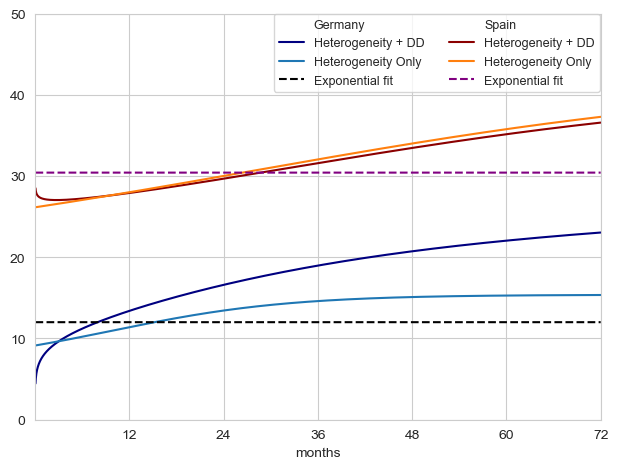

In [13]:
from matplotlib.lines import Line2D

colors = sn.color_palette()
_trim = 360  # drop noisy tail from T=500 arrays; xlim=72 anyway

plt.figure()
# Germany
plt.plot(t_months,ger_inv_h_ksame,    c="navy")
plt.plot(t_months,ger_inv_h_k1,   c="tab:blue")
plt.plot(t_months,ger_inv_h_expo, c="black",  ls="--")
# Spain (spa_h_expo_sim is T=200, no trim needed)
plt.plot(t_months,spa_inv_h_ksame,    c="darkred")
plt.plot(t_months,spa_inv_h_k1,   c=colors[1])
plt.plot(t_months,spa_inv_h_expo,          c="purple", ls="--")

plt.xlim(0, 72); plt.ylim(0, 50)
plt.xticks(range(12, 73, 12))
plt.xlabel("months")

legend_elements = [
    Line2D([0],[0], color="none",     label="Germany"),
    Line2D([0],[0], color="navy",     label="Heterogeneity + DD"),
    Line2D([0],[0], color="tab:blue", label="Heterogeneity Only"),
    Line2D([0],[0], color="black",    linestyle="--", label="Exponential fit"),
    Line2D([0],[0], color="none",     label="Spain"),
    Line2D([0],[0], color="darkred",  label="Heterogeneity + DD"),
    Line2D([0],[0], color=colors[1],  label="Heterogeneity Only"),
    Line2D([0],[0], color="purple",   linestyle="--", label="Exponential fit"),
]
plt.legend(handles=legend_elements, loc="upper center",
           bbox_to_anchor=(0.71, 1.015), ncol=2, fontsize=9)
plt.tight_layout()
plt.savefig("./output/figures/exp_dur_base_a.png", bbox_inches="tight")
plt.show()

In [17]:
# appentenship needed or not
# "pending unemployed" for temp workers 1999 in Germany - email


### Figure 3: Same but for only temporary spells

In [14]:
# Fine grid: 1 day to 72 months, 5000 points
t_days   = np.linspace(1, 72 * 30, 5_000)
t_months = t_days / 30

# Spain
spa_inv_h_ksameT = inv_hazard_weibull_mix(t_days, spa_lambdaT_0, spa_alphaT_0, spa_kT_0) / 30
spa_inv_h_k1T    = inv_hazard_weibull_mix(t_days, spa_lambdaT_0, spa_alphaT_0, 1.0)     / 30
spa_inv_h_expoT  = np.full_like(t_days, spa_momsT[0] / 30)  # flat: mu_y in months

# Germany
ger_inv_h_ksameT = inv_hazard_weibull_mix(t_days, ger_lambdaT_0, ger_alphaT_0, ger_kT_0) / 30
ger_inv_h_k1T    = inv_hazard_weibull_mix(t_days, ger_lambdaT_0, ger_alphaT_0, 1.0)     / 30
ger_inv_h_expoT  = np.full_like(t_days, ger_momsT[0] / 30)

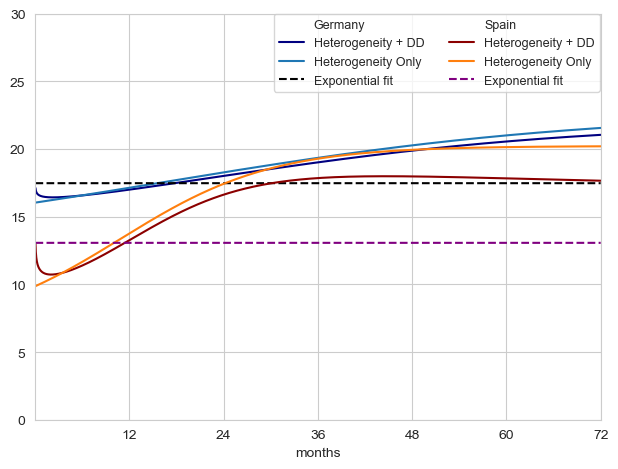

In [15]:
from matplotlib.lines import Line2D

colors = sn.color_palette()
_trim = 360  # drop noisy tail from T=500 arrays; xlim=72 anyway

plt.figure()
# Germany
plt.plot(t_months,ger_inv_h_ksameT,    c="navy")
plt.plot(t_months,ger_inv_h_k1T,   c="tab:blue")
plt.plot(t_months,ger_inv_h_expoT, c="black",  ls="--")
# Spain (spa_h_expo_sim is T=200, no trim needed)
plt.plot(t_months,spa_inv_h_ksameT,    c="darkred")
plt.plot(t_months,spa_inv_h_k1T,   c=colors[1])
plt.plot(t_months,spa_inv_h_expoT,          c="purple", ls="--")

plt.xlim(0, 72); plt.ylim(0, 30)
plt.xticks(range(12, 73, 12))
plt.xlabel("months")

legend_elements = [
    Line2D([0],[0], color="none",     label="Germany"),
    Line2D([0],[0], color="navy",     label="Heterogeneity + DD"),
    Line2D([0],[0], color="tab:blue", label="Heterogeneity Only"),
    Line2D([0],[0], color="black",    linestyle="--", label="Exponential fit"),
    Line2D([0],[0], color="none",     label="Spain"),
    Line2D([0],[0], color="darkred",  label="Heterogeneity + DD"),
    Line2D([0],[0], color=colors[1],  label="Heterogeneity Only"),
    Line2D([0],[0], color="purple",   linestyle="--", label="Exponential fit"),
]
plt.legend(handles=legend_elements, loc="upper center",
           bbox_to_anchor=(0.71, 1.015), ncol=2, fontsize=9)
plt.tight_layout()
plt.savefig("./output/figures/exp_dur_T_a.png", bbox_inches="tight")
plt.show()

## Appendix figure

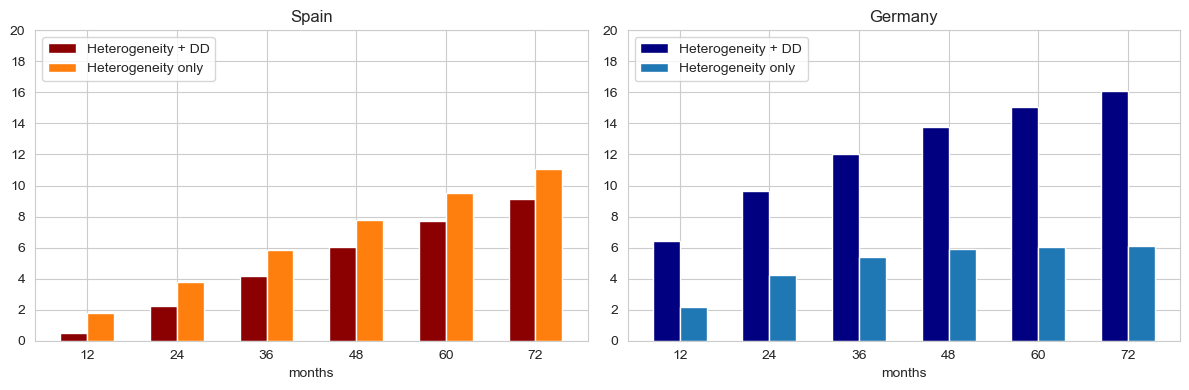

In [16]:
months = [12, 24, 36, 48, 60, 72]
month_labels = ["12","24","36","48","60","72"]
x = np.arange(6)

fig, (ax_spa, ax_ger) = plt.subplots(1, 2, figsize=(12, 4))

# Spain
months_bar = np.array([12, 24, 36, 48, 60, 72])
t_bar_days = months_bar * 30

# New entrant baseline: t ≈ 0+; use 0.5 months (midpoint of first histogram bin)
# to match what the old simulation's index [0] represented
t0_days = np.array([0.5 * 30])

# Spain
spa_ksame_bar = inv_hazard_weibull_mix(t_bar_days, spa_lambda_0, spa_alpha_0, spa_k_0) / 30
spa_k1_bar    = inv_hazard_weibull_mix(t_bar_days, spa_lambda_0, spa_alpha_0, 1.0)     / 30
spa_ksame_0   = inv_hazard_weibull_mix(t0_days,    spa_lambda_0, spa_alpha_0, spa_k_0)[0] / 30
spa_k1_0      = inv_hazard_weibull_mix(t0_days,    spa_lambda_0, spa_alpha_0, 1.0)[0]     / 30

# Germany
ger_ksame_bar = inv_hazard_weibull_mix(t_bar_days, ger_lambda_0, ger_alpha_0, ger_k_0) / 30
ger_k1_bar    = inv_hazard_weibull_mix(t_bar_days, ger_lambda_0, ger_alpha_0, 1.0)     / 30
ger_ksame_0   = inv_hazard_weibull_mix(t0_days,    ger_lambda_0, ger_alpha_0, ger_k_0)[0] / 30
ger_k1_0      = inv_hazard_weibull_mix(t0_days,    ger_lambda_0, ger_alpha_0, 1.0)[0]     / 30


ax_spa.bar(x,       spa_ksame_bar - spa_ksame_0, width=0.3, label="Heterogeneity + DD",  color="darkred")
ax_spa.bar(x + 0.3, spa_k1_bar    - spa_k1_0,    width=0.3, label="Heterogeneity only", color="tab:orange")
ax_spa.set_ylim(0, 20); ax_spa.set_yticks(np.arange(0,21,2)), ax_spa.legend(loc="upper left")
ax_spa.set_xticks(x + 0.15); ax_spa.set_xticklabels(month_labels)
ax_spa.set_xlabel("months"); ax_spa.set_title("Spain")

ax_ger.bar(x,       ger_ksame_bar - ger_ksame_0, width=0.3, label="Heterogeneity + DD",  color="navy")
ax_ger.bar(x + 0.3, ger_k1_bar    - ger_k1_0,    width=0.3, label="Heterogeneity only", color="tab:blue")
ax_ger.set_ylim(0, 20); ax_ger.set_yticks(np.arange(0,21,2)), ax_ger.legend(loc="upper left")
ax_ger.set_xticks(x + 0.15); ax_ger.set_xticklabels(month_labels)
ax_ger.set_xlabel("months"); ax_ger.set_title("Germany")

plt.tight_layout()
plt.savefig("./output/figures/het_DD_base_a.png")
plt.show()

## Spain: Hazard Simulation

To confirm our derivations above, we reproduce the same figure but with a simulation.

- **`spa_h_expo_sim`**: exponential fit on an initial 1M-draw histogram (T=200 months).
- **`spa_sur_sim`, `spa_sur_sim0`**: 101 batches x 1M draws, T=500 months, for smooth hazard curves.

In [17]:
# Initial 1M sample — used only for the exponential lambda fit
_T_expo = 200
np.random.seed(42)
_spa_init = np.vstack((
    weibull.rvs(c=spa_k_0, scale=spa_lambda_0,             size=(500_000, 2)),
    weibull.rvs(c=spa_k_0, scale=spa_lambda_0*spa_alpha_0, size=(500_000, 2)))).ravel()

_h_init, _ = np.histogram(_spa_init/30, bins=np.arange(0, _T_expo, 1))
_h_init     = _h_init / np.sum(_h_init)
_adj        = least_squares(ssr_cdf, 0.04, args=(np.cumsum(_h_init), 1))
spa_h_expo_sim = (np.diff(expo_cdf(_adj.x[0], max_dur=_T_expo)) /
                  (1 - expo_cdf(_adj.x[0], max_dur=_T_expo)[:-1]))
print(f"Spain exponential lambda: {_adj.x[0]:.6f}  (mean = {1/_adj.x[0]:.1f} months)")

Spain exponential lambda: 0.034481  (mean = 29.0 months)


In [18]:
# 101 batches x 1M draws — smooth hazard curves at T=500 months
_N = 1_000_000
_T = 500

spa_sample_mix  = np.vstack((
    weibull.rvs(c=spa_k_0, scale=spa_lambda_0,             size=(_N//2, 2)),
    weibull.rvs(c=spa_k_0, scale=spa_lambda_0*spa_alpha_0, size=(_N//2, 2))))
spa_sample_mix0 = np.vstack((
    weibull.rvs(c=1,       scale=spa_lambda_0,             size=(_N//2, 2)),
    weibull.rvs(c=1,       scale=spa_lambda_0*spa_alpha_0, size=(_N//2, 2))))

for _ in range(100):
    spa_sample_mix  = np.vstack((spa_sample_mix, np.vstack((
        weibull.rvs(c=spa_k_0, scale=spa_lambda_0,             size=(_N//2, 2)),
        weibull.rvs(c=spa_k_0, scale=spa_lambda_0*spa_alpha_0, size=(_N//2, 2))))))
    spa_sample_mix0 = np.vstack((spa_sample_mix0, np.vstack((
        weibull.rvs(c=1,       scale=spa_lambda_0,             size=(_N//2, 2)),
        weibull.rvs(c=1,       scale=spa_lambda_0*spa_alpha_0, size=(_N//2, 2))))))

_h,  _ = np.histogram(spa_sample_mix.ravel()/30,  bins=np.arange(0, _T, 1))
_h0, _ = np.histogram(spa_sample_mix0.ravel()/30, bins=np.arange(0, _T, 1))
_h,  _h0 = _h/np.sum(_h), _h0/np.sum(_h0)

spa_sur_sim  = _h[:-1]  / (1 - np.cumsum(_h)[:-1])   # Het + DD
spa_sur_sim0 = _h0[:-1] / (1 - np.cumsum(_h0)[:-1])  # Het only (k=1)

print("Spain large simulation complete.")
print(f"  Het+DD   month 1: {1/spa_sur_sim[0]:.2f} expected months remaining")
print(f"  Het only month 1: {1/spa_sur_sim0[0]:.2f} expected months remaining")

Spain large simulation complete.
  Het+DD   month 1: 27.04 expected months remaining
  Het only month 1: 25.73 expected months remaining


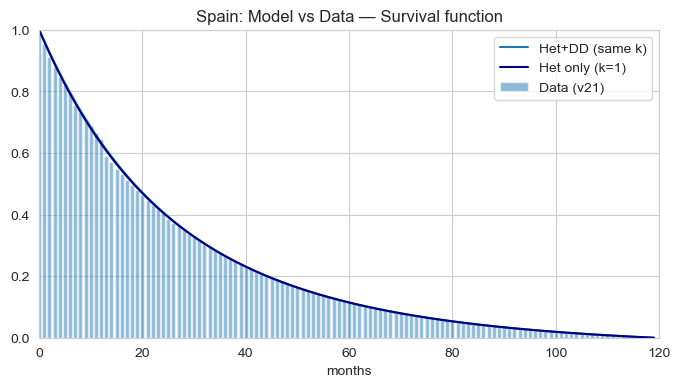

In [19]:
spa_raw = pd.read_csv("./data/raw/spain/duration/dur_2011_T_v21.csv")

_T_p = 120
_bins_p = np.arange(0, _T_p, 1)
_h_data, _ = np.histogram(spa_raw.days.values/30, bins=_bins_p)
_h_sp,   _ = np.histogram(spa_sample_mix.ravel()/30,  bins=_bins_p)
_h_sp0,  _ = np.histogram(spa_sample_mix0.ravel()/30, bins=_bins_p)
_h_data, _h_sp, _h_sp0 = _h_data/np.sum(_h_data), _h_sp/np.sum(_h_sp), _h_sp0/np.sum(_h_sp0)

plt.figure(figsize=(8, 4))
plt.bar(_bins_p, np.hstack((1, 1-np.cumsum(_h_data))), alpha=0.5, label="Data (v21)")
plt.plot(_bins_p, np.hstack((1, 1-np.cumsum(_h_sp))),  label="Het+DD (same k)")
plt.plot(_bins_p, np.hstack((1, 1-np.cumsum(_h_sp0))), c="navy", label="Het only (k=1)")
plt.xlim(0, _T_p); plt.ylim(0, 1)
plt.xlabel("months"); plt.title("Spain: Model vs Data — Survival function")
plt.legend(); plt.show()

In [20]:
np.savetxt("spa_sim_invHaz_ksame_21a.csv", 1/spa_sur_sim,    delimiter=",")
np.savetxt("spa_sim_invHaz_k1_21a.csv",    1/spa_sur_sim0,   delimiter=",")
np.savetxt("spa_sim_invHaz_expo_21a.csv",  1/spa_h_expo_sim, delimiter=",")
print("Spain intermediate files saved (_21a suffix).")

Spain intermediate files saved (_21a suffix).


## Germany: Hazard Simulation

Single batch of 1M draws (T=500). Germany spells are much shorter than Spain's, so a single batch gives sufficient smoothness.

In [21]:
_T_ger = 500
_N_ger = 1_000_000
np.random.seed(42)

ger_sample_mix  = np.vstack((
    weibull.rvs(c=ger_k_0, scale=ger_lambda_0,             size=(_N_ger//2, 2)),
    weibull.rvs(c=ger_k_0, scale=ger_lambda_0*ger_alpha_0, size=(_N_ger//2, 2))))
ger_sample_mix0 = np.vstack((
    weibull.rvs(c=1,       scale=ger_lambda_0,             size=(_N_ger//2, 2)),
    weibull.rvs(c=1,       scale=ger_lambda_0*ger_alpha_0, size=(_N_ger//2, 2))))

_h_ger,  _ = np.histogram(ger_sample_mix.ravel()/30,  bins=np.arange(0, _T_ger, 1))
_h_ger0, _ = np.histogram(ger_sample_mix0.ravel()/30, bins=np.arange(0, _T_ger, 1))
_h_ger,  _h_ger0 = _h_ger/np.sum(_h_ger), _h_ger0/np.sum(_h_ger0)

# Exponential fit on full T=500 histogram
_ger_adj = least_squares(ssr_cdf, 0.04, args=(np.cumsum(_h_ger), 1))
ger_h_expo_sim = (np.diff(expo_cdf(_ger_adj.x[0], max_dur=_T_ger)) /
                  (1 - expo_cdf(_ger_adj.x[0], max_dur=_T_ger)[:-1]))

ger_sur_sim  = _h_ger[:-1]  / (1 - np.cumsum(_h_ger)[:-1])   # Het + DD
ger_sur_sim0 = _h_ger0[:-1] / (1 - np.cumsum(_h_ger0)[:-1])  # Het only (k=1)

print("Germany simulation complete.")
print(f"  Het+DD   month 1: {1/ger_sur_sim[0]:.2f} expected months remaining")
print(f"  Het only month 1: {1/ger_sur_sim0[0]:.2f} expected months remaining")

Germany simulation complete.
  Het+DD   month 1: 6.05 expected months remaining
  Het only month 1: 8.72 expected months remaining


C:\Users\Cristina Lafuente\AppData\Local\Temp\ipykernel_2128\2656688380.py:18: RuntimeWarning: invalid value encountered in divide
  ger_h_expo_sim = (np.diff(expo_cdf(_ger_adj.x[0], max_dur=_T_ger)) /


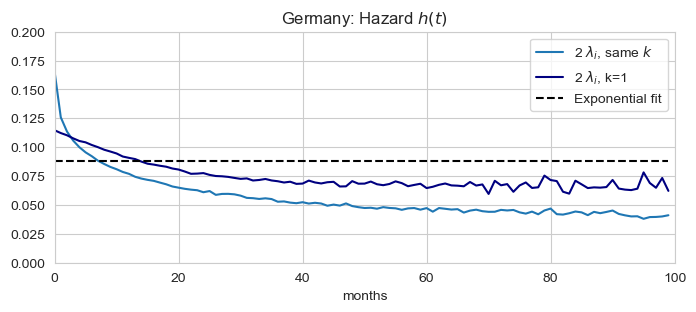

In [22]:
plt.figure(figsize=(8, 3))
plt.plot(ger_sur_sim[:100],    label=r"2 $\lambda_i$, same $k$")
plt.plot(ger_sur_sim0[:100],   label=r"2 $\lambda_i$, k=1",   c="navy")
plt.plot(ger_h_expo_sim[:100], label="Exponential fit",         c="black", ls="--")
plt.title(r"Germany: Hazard $h(t)$")
plt.ylim(0, 0.2); plt.xlim(0, 100); plt.xlabel("months")
plt.legend(); plt.show()

In [23]:
np.savetxt("ger_sim_invHaz_ksame_a.csv", 1/ger_sur_sim,    delimiter=",")
np.savetxt("ger_sim_invHaz_k1_a.csv",    1/ger_sur_sim0,   delimiter=",")
np.savetxt("ger_sim_invHaz_expo_a.csv",  1/ger_h_expo_sim, delimiter=",")
print("Germany intermediate files saved (suffix _a).")

Germany intermediate files saved (suffix _a).


C:\Users\Cristina Lafuente\AppData\Local\Temp\ipykernel_2128\3774694514.py:1: RuntimeWarning: divide by zero encountered in divide
  np.savetxt("ger_sim_invHaz_ksame_a.csv", 1/ger_sur_sim,    delimiter=",")
C:\Users\Cristina Lafuente\AppData\Local\Temp\ipykernel_2128\3774694514.py:2: RuntimeWarning: divide by zero encountered in divide
  np.savetxt("ger_sim_invHaz_k1_a.csv",    1/ger_sur_sim0,   delimiter=",")
C:\Users\Cristina Lafuente\AppData\Local\Temp\ipykernel_2128\3774694514.py:3: RuntimeWarning: divide by zero encountered in divide
  np.savetxt("ger_sim_invHaz_expo_a.csv",  1/ger_h_expo_sim, delimiter=",")


## Reproducing Figure 2: Expected months in an unstable spell

Spain variables used directly — no file reload needed within this notebook.

In [24]:
# Numbers cited in the paper text
months = [12, 24, 36, 48, 60, 72]
print("Spain — Het+DD:  ", np.round(1/spa_sur_sim[months], 2))
print("Spain — Het only:", np.round(1/spa_sur_sim0[months], 2))
print("Germany — Het+DD:  ", np.round(1/ger_sur_sim[months], 2))
print("Germany — Het only:", np.round(1/ger_sur_sim0[months], 2))
print(f"\nAt 24 months elapsed:")
print(f"  Spain Het+DD={1/spa_sur_sim[24]:.2f}  Het only={1/spa_sur_sim0[24]:.2f}")
print(f"  Germany Het+DD={1/ger_sur_sim[24]:.2f}  Het only={1/ger_sur_sim0[24]:.2f}")

Spain — Het+DD:   [27.49 29.25 31.16 33.05 34.75 36.15]
Spain — Het only: [27.58 29.58 31.65 33.59 35.36 36.92]
Germany — Het+DD:   [12.99 16.39 18.94 20.39 21.14 21.85]
Germany — Het only: [11.02 12.89 14.17 14.16 15.47 14.92]

At 24 months elapsed:
  Spain Het+DD=29.25  Het only=29.58
  Germany Het+DD=16.39  Het only=12.89


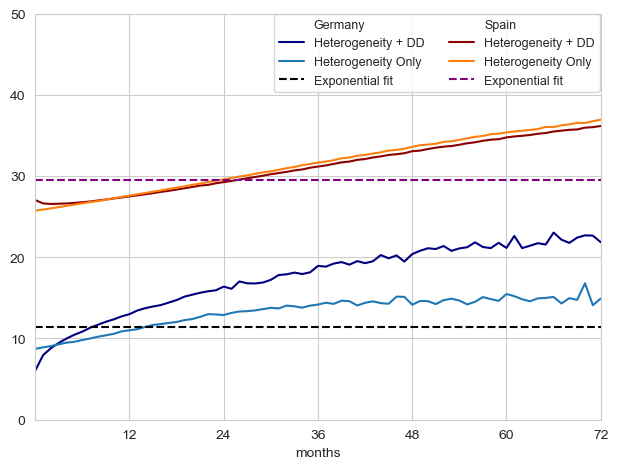

In [25]:
from matplotlib.lines import Line2D

colors = sn.color_palette()
_trim = 360  # drop noisy tail from T=500 arrays; xlim=72 anyway

plt.figure()
# Germany
plt.plot(1/ger_sur_sim[:-_trim],    c="navy")
plt.plot(1/ger_sur_sim0[:-_trim],   c="tab:blue")
plt.plot(1/ger_h_expo_sim[:-_trim], c="black",  ls="--")
# Spain (spa_h_expo_sim is T=200, no trim needed)
plt.plot(1/spa_sur_sim[:-_trim],    c="darkred")
plt.plot(1/spa_sur_sim0[:-_trim],   c=colors[1])
plt.plot(1/spa_h_expo_sim,          c="purple", ls="--")

plt.xlim(0, 72); plt.ylim(0, 50)
plt.xticks(range(12, 73, 12))
plt.xlabel("months")

legend_elements = [
    Line2D([0],[0], color="none",     label="Germany"),
    Line2D([0],[0], color="navy",     label="Heterogeneity + DD"),
    Line2D([0],[0], color="tab:blue", label="Heterogeneity Only"),
    Line2D([0],[0], color="black",    linestyle="--", label="Exponential fit"),
    Line2D([0],[0], color="none",     label="Spain"),
    Line2D([0],[0], color="darkred",  label="Heterogeneity + DD"),
    Line2D([0],[0], color=colors[1],  label="Heterogeneity Only"),
    Line2D([0],[0], color="purple",   linestyle="--", label="Exponential fit"),
]
plt.legend(handles=legend_elements, loc="upper center",
           bbox_to_anchor=(0.71, 1.015), ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

## Appendix Figure: Heterogeneity vs Duration Dependence

Bar chart: expected additional months relative to a new entrant, comparing Het+DD vs Het only at elapsed durations 12–72 months.

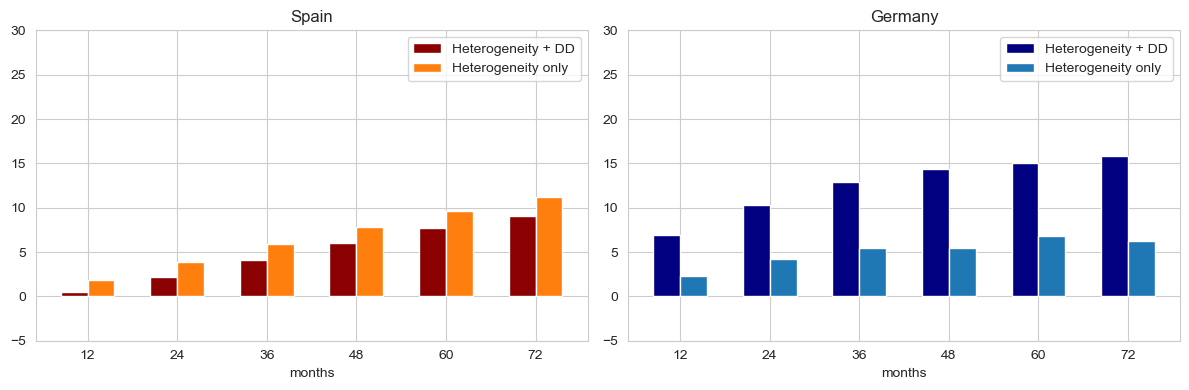

In [26]:
months = [12, 24, 36, 48, 60, 72]
month_labels = ["12","24","36","48","60","72"]
x = np.arange(6)

fig, (ax_spa, ax_ger) = plt.subplots(1, 2, figsize=(12, 4))

# Spain
ax_spa.bar(x,       1/spa_sur_sim[months]  - 1/spa_sur_sim[0],  width=0.3,
           label="Heterogeneity + DD",  color="darkred")
ax_spa.bar(x + 0.3, 1/spa_sur_sim0[months] - 1/spa_sur_sim0[0], width=0.3,
           label="Heterogeneity only", color="tab:orange")
ax_spa.set_xticks(x + 0.15); ax_spa.set_xticklabels(month_labels)
ax_spa.set_xlabel("months"); ax_spa.set_title("Spain")
ax_spa.set_ylim(-5, 30); ax_spa.legend()

# Germany
ax_ger.bar(x,       1/ger_sur_sim[months]  - 1/ger_sur_sim[0],  width=0.3,
           label="Heterogeneity + DD",  color="navy")
ax_ger.bar(x + 0.3, 1/ger_sur_sim0[months] - 1/ger_sur_sim0[0], width=0.3,
           label="Heterogeneity only", color="tab:blue")
ax_ger.set_xticks(x + 0.15); ax_ger.set_xticklabels(month_labels)
ax_ger.set_xlabel("months"); ax_ger.set_title("Germany")
ax_ger.set_ylim(-5, 30); ax_ger.legend()

plt.tight_layout()
# plt.savefig("./data/intermediate/germany/het_DD_base_a.png")
plt.show()